# Extraction of stream banks and channel geometry from a lidar-derived DTM with GRASS

*Case study notebook accompanying the manuscript on GRASS as a geocomputational engine
(Progress in Physical Geography, special issue on open source computing).*

## Overview

Stream banks mark the transition between the channel and the adjacent floodplain.
Their position and height control channel width, bankfull capacity and the exposure of the floodplain to inundation,
and they are therefore a basic input to stream restoration design, erosion assessment and flood modeling.
Lidar-derived digital terrain models (DTMs) resolve the break in slope at the top of a bank at sub-meter resolution,
but extracting a continuous bank line from that signal requires a combination of hydrological, geomorphometric,
raster and vector operations that no single tool provides.

This case study extracts both banks of Bear Creek in Chatham County, North Carolina, USA,
along the full length of its headwater watershed (approximately 21 km), and derives channel width, bank height and
channel asymmetry along the stream. The analysis chains together tools from several domains of GRASS:

| Step | GRASS functionality |
|---|---|
| Data acquisition and management | `gs.create_project`, `r.import`, `v.in.ags` addon, `r.in.wms`, `g.region` |
| Terrain visualization | `r.relief`, `r.skyview` addon, `r.blend`, display tools (`d.*`) |
| Stream network delineation | `r.watershed`, `r.stream.order` addon |
| Vector processing | `v.extract`, `v.build.polylines`, `v.geometry`, `v.generalize`, `v.buffer`, `v.to.rast`, `v.in.region` |
| Geomorphometry and map algebra | `r.param.scale`, `r.mapcalc`, raster masks |
| Least cost path analysis | `v.segment`, `r.cost`, `r.path` |
| Channel geometry | `r.stream.distance` addon, `v.to.points`, `v.what.rast`, `v.distance` |
| Interoperability | JSON output consumed by pandas; rendering with `grass.jupyter`, matplotlib and Pillow |

The workflow is driven entirely from Python through the GRASS Tools API; the computational region and mask
are managed with context managers, and tool outputs are exchanged with the Python ecosystem as JSON.
Processing the 140 million cell DTM in this notebook takes on the order of tens of minutes on a desktop computer.

**Software requirements.** GRASS 8.6 or later (the Tools API, `MaskManager`, `RegionManager` and `v.geometry`),
the addons `v.in.ags`, `r.skyview`, `r.stream.order` and `r.stream.distance` (installed below), and the Python packages pandas, matplotlib, Pillow and folium (for the interactive maps).

In [1]:
import io
import sys
import subprocess
import urllib.request
import zipfile
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Locate the GRASS Python package and import it
sys.path.append(
    subprocess.check_output(["grass", "--config", "python_path"], text=True).strip()
)
import grass.script as gs
import grass.jupyter as gj
from grass.tools import Tools

## 1. Study area and data

The study area is the *Headwaters Bear Creek* watershed (hydrologic unit code 030300030507, 66 km²)
in the Piedmont of North Carolina. The watershed is a 12-digit hydrologic unit of the
[Watershed Boundary Dataset (WBD)](https://www.usgs.gov/national-hydrography/watershed-boundary-dataset);
the mapped course of Bear Creek is taken from the
[National Hydrography Dataset (NHD)](https://www.usgs.gov/national-hydrography/national-hydrography-dataset)
for comparison with the stream derived from the terrain.

The terrain data is a bare-earth DTM derived from Quality Level 1 lidar acquired in 2024, distributed as a countywide
GeoTIFF with 3.125 ft (0.95 m) resolution by the North Carolina Emergency Management
[Spatial Data Download](https://sdd.nc.gov/) portal. Its coordinate reference system (CRS) is NAD83(2011) / North Carolina (EPSG:6543)
with horizontal and vertical units in US survey feet. The analysis is therefore carried out in feet, the native units of the data,
and results are converted to meters for reporting.

Within the channel itself, the DTM does not represent the stream bed. Lidar pulses do not penetrate water, so the surface in the channel
is either hydro-flattened to a level water surface, which appears as flat reaches, or interpolated across sparse returns, which produces
triangular facets between the few points available. Both artifacts are visible in the shaded relief along Bear Creek. They do not affect
the bank edges, which are above the water surface, but they do affect the elevation of the channel bottom derived below and the drainage
directions computed through the flat reaches.

| Dataset | Source | Content used |
|---|---|---|
| Chatham County 2024 QL1 DTM | NC Emergency Management, https://sdd.nc.gov/ | Elevation, 3.125 ft resolution, 8.6 GB GeoTIFF |
| Watershed Boundary Dataset | USGS National Map, hydro.nationalmap.gov map service | HUC12 polygon 030300030507 |
| National Hydrography Dataset | USGS National Map, hydro.nationalmap.gov map service | Flowlines named *Bear Creek* |
| NAIP orthoimagery | USGS National Map, imagery.nationalmap.gov WMS | Orthophoto for land cover context, 30 ft resolution |
| County boundaries | US Census Bureau TIGERweb map service | North Carolina counties for the locator map |

### 1.1 GRASS project

A GRASS *project* holds all data of an analysis in a single CRS. The analysis can be started in two ways:

- **From the prepared GRASS project** archived on Zenodo ([doi:10.5281/zenodo.23600243](https://doi.org/10.5281/zenodo.23600243), 1.5 GB),
  which contains the DTM subset (`dtm`), its sky-view factor (`skyview`, Section 1.4), the orthophoto (`ortho`), the watershed (`basin`),
  the NHD flowline (`bear_creek`) and the county boundaries (`nc_counties`). The cell below downloads and unpacks the archive into
  `data_dir` when the project is not found there, and the data acquisition cells of Section 1.2 are skipped.
- **From the original sources.** Set `build_from_source = True` and download the
  [countywide DTM](https://sdd.nc.gov/downloads/public/DEMMosaicsbyCounty/DEM03_CountywideRasters/Chatham_2024_QL1_03ft_CountywideRaster.zip)
  from the NCEM portal into `data_dir`; the project is then created from the CRS of the GeoTIFF and the remaining inputs are
  retrieved from USGS and Census Bureau map services in Section 1.2.

In [2]:
data_dir = Path("/path/to/data")
project = data_dir / "chatham_northcarolina_usa_epsg6543"
dtm_file = data_dir / "Chatham_2024_QL1_03ft_CountywideRaster.tif"

# Set to True to rebuild the project from the original sources (Section 1.2)
build_from_source = False

if build_from_source:
    # The project inherits the CRS of the GeoTIFF
    gs.create_project(project, filename=dtm_file)
elif not project.exists():
    # Download the prepared project from Zenodo (1.5 GB) and unpack it into data_dir
    url = "https://zenodo.org/records/23600244/files/chatham_northcarolina_usa_epsg6543.zip?download=1"
    archive, _ = urllib.request.urlretrieve(url)
    with zipfile.ZipFile(archive) as zip_ref:
        zip_ref.extractall(data_dir)
    Path(archive).unlink()

session = gj.init(project)
tools = Tools()
print("GRASS", gs.version()["version"])
tools.g_proj(flags="p", format="projjson")["name"]

GRASS 8.6.0dev


'NAD83(2011) / North Carolina (ftUS) + NAVD88 height (ftUS)'

### 1.2 Acquiring data from the original sources

The cells in this section run only when `build_from_source` is set; with the prepared project, all of these maps are already present.
The watershed polygon and the flowlines are retrieved directly from the USGS ArcGIS REST services with the
[v.in.ags](https://grass.osgeo.org/grass-devel/manuals/addons/v.in.ags.html) addon, which requests
only the features matching an attribute query and reprojects them into the project CRS on import.
Since the name *Bear Creek* is not unique nationally, the flowline query is restricted to the bounding box of the watershed,
obtained in geographic coordinates from `g.region`, and the result is clipped to the watershed.

In [3]:
if build_from_source:
    tools.g_extension(extension="v.in.ags")
    tools.v_in_ags(
        url="https://hydro.nationalmap.gov/arcgis/rest/services/wbd/MapServer/6/",
        where="huc12 = '030300030507'",
        output="basin",
    )
    bbox = tools.g_region(vector="basin", flags="b", format="json")
    tools.v_in_ags(
        url="https://hydro.nationalmap.gov/arcgis/rest/services/nhd/MapServer/6/",
        where="gnis_name = 'Bear Creek'",
        bbox_filter=f"{bbox['ll_w']},{bbox['ll_s']},{bbox['ll_e']},{bbox['ll_n']}",
        output="creek",
    )
    tools.v_clip(input="creek", clip="basin", output="bear_creek")

The countywide DTM is subset on import using the *computational region*, the GRASS mechanism that defines
the extent and resolution of all raster operations. The region is set to the watershed extent enlarged by 1000 ft
(the `grow` option is expressed in cells, hence the temporary 1 ft resolution) so that the watershed is fully covered, and
[r.import](https://grass.osgeo.org/grass-stable/manuals/r.import.html) reads only that window of the GeoTIFF at its native resolution.
The resulting raster has 10 307 rows and 13 641 columns (140.6 million cells).

In [4]:
if build_from_source:
    tools.g_region(vector="basin", res=1, grow=1000)
    tools.r_import(input=dtm_file, output="dtm", extent="region")

Should the USGS map services be unavailable, the same two vector maps can be imported from the statewide
[NHD GeoPackage for North Carolina](https://prd-tnm.s3.amazonaws.com/StagedProducts/Hydrography/NHD/State/GPKG/NHD_H_North_Carolina_State_GPKG.zip)
(2.4 GB) with `v.import`, which reprojects from the geographic CRS of the GeoPackage:

```python
tools.v_import(input="NHD_H_North_Carolina_State_GPKG.gpkg", layer="WBDHU12",
               where="huc12 = '030300030507'", output="basin")
tools.v_import(input="NHD_H_North_Carolina_State_GPKG.gpkg", layer="NHDFlowline",
               where="gnis_name = 'Bear Creek'", output="creek")
tools.v_clip(input="creek", clip="basin", output="bear_creek")
```

For visual context on land cover, an orthophoto from the National Agriculture Imagery Program (NAIP) is retrieved from the USGS
[NAIP imagery service](https://imagery.nationalmap.gov/arcgis/rest/services/USGSNAIPImagery/ImageServer) with
[r.in.wms](https://grass.osgeo.org/grass-stable/manuals/r.in.wms.html), which requests the imagery for the current computational region.
The full NAIP resolution is not needed, so the region is set to the DTM extent at a coarser 30 ft cell size to limit the download.
The service mosaics imagery from different flights and dates, so colors and shading are inconsistent across flight line seams;
the orthophoto serves only as land cover context.
The county boundaries of North Carolina, used for the locator map in the overview figure, are retrieved from the US Census Bureau
[TIGERweb](https://tigerweb.geo.census.gov/) map service, again with v.in.ags.

In [5]:
if build_from_source:
    tools.g_region(raster="dtm", res=30)
    tools.r_in_wms(
        url="https://imagery.nationalmap.gov/arcgis/services/USGSNAIPImagery/ImageServer/WMSServer",
        out="ortho",
        layer="USGSNAIPImagery",
    )

In [6]:
if build_from_source:
    tools.v_in_ags(
        url="https://tigerweb.geo.census.gov/arcgis/rest/services/Generalized_ACS2024/State_County/MapServer/12",
        where="STATE='37'",
        output="nc_counties",
    )

### 1.3 Computational region and visualization

From this point on, the computational region is aligned with the DTM. A shaded relief map is computed with
[r.relief](https://grass.osgeo.org/grass-stable/manuals/r.relief.html) for visualization and a color table is assigned to the DTM.

In [7]:
tools.g_region(raster="dtm")
tools.r_colors(map="dtm", color="srtm_percent")
tools.r_relief(input="dtm", output="relief")

The watershed and the NHD flowline are first displayed in an interactive map over OpenStreetMap tiles.

In [8]:
study_area = gj.InteractiveMap(width=1000)
study_area.add_vector("basin")
study_area.add_vector("bear_creek")
study_area.show()

Several steps of the analysis and most of the figures are restricted to the watershed. The watershed polygon is rasterized with
[v.to.rast](https://grass.osgeo.org/grass-stable/manuals/v.to.rast.html) into `basin_mask`, a raster that is applied as a *mask*
where needed through the `MaskManager` context manager, which activates the mask for the duration of a block of code only.

In [9]:
tools.v_to_rast(input="basin", output="basin_mask", use="value")

Detail views of the results are rendered for selected reaches of the stream. The extent of each reach is stored as a *named region*
with [g.region](https://grass.osgeo.org/grass-stable/manuals/g.region.html), so that any figure can be rendered for the same extent by
activating the region through the `RegionManager` context manager; [v.in.region](https://grass.osgeo.org/grass-stable/manuals/v.in.region.html)
creates a polygon outlining the reach for display in overview maps.
Two reaches are used: reach A in the middle of the stream, selected because its channel shows both types of artifacts of the DTM
described in Section 1, a hydro-flattened water surface in one part and triangular facets in the other, and reach B at the outlet of
the watershed, where the least cost paths start. Their outlines are labeled in the overview map with `d.text`.

In [10]:
tools.g_region(n=676000, s=674800, e=1885100, w=1883000, save="zoom_1")
with gs.RegionManager(region="zoom_1"):
    tools.v_in_region(output="zoom_1", type="area")
tools.g_region(n=677200, s=675950, e=1888000, w=1885900, save="zoom_2")
with gs.RegionManager(region="zoom_2"):
    tools.v_in_region(output="zoom_2", type="area")

The overview map combines the orthophoto with the shaded relief inside the watershed (the mask is active during rendering),
the NHD course of Bear Creek and the extents of the two detail reaches. Legend entries are defined by the `legend_label` option of
`d.vect` and drawn by `d.legend_vect`. A locator map of North Carolina, with its counties and Chatham County filled, is rendered as a second, small `Map` for the
extent of the county boundaries, and the two images are composited with Pillow: the rendered file of the main map (`Map.filename`)
is opened, the locator is pasted into its lower right corner, and the file is written back before display.

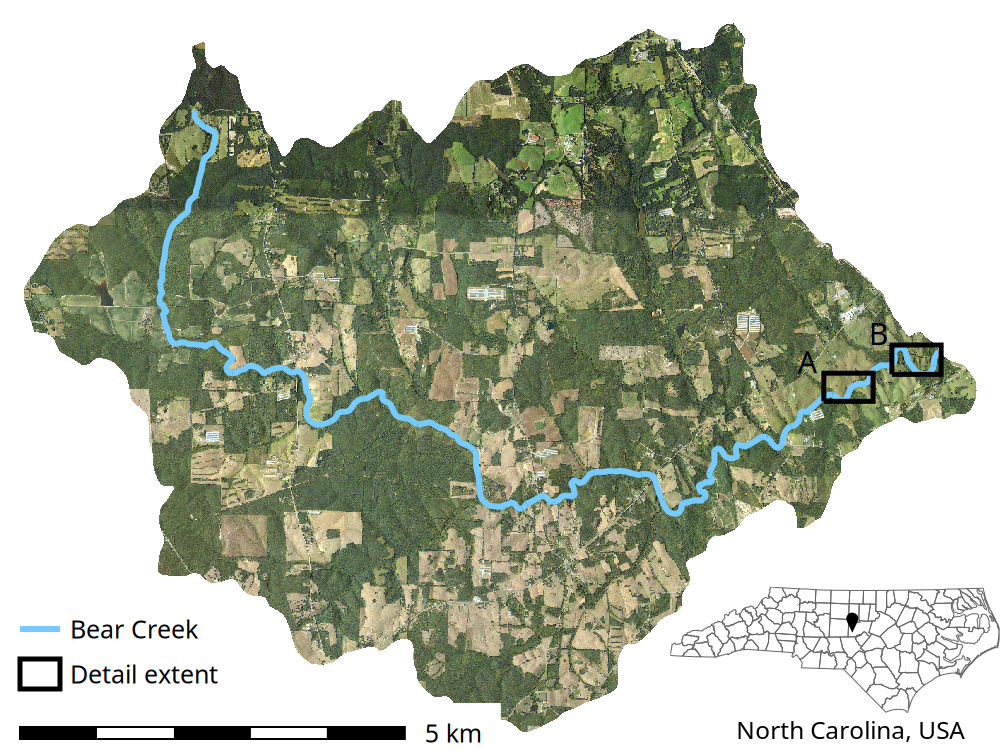

In [11]:
with gs.MaskManager("basin_mask"):
    study_area = gj.Map(width=1000)
    study_area.d_shade(color="ortho", shade="relief", brighten=60)
    study_area.d_vect(map="bear_creek", width=6, color="#77caf9", legend_label="Bear Creek")
    study_area.d_vect(map="zoom_1", width=5, color="black", fill_color="none", legend_label="Detail extent")
    study_area.d_vect(map="zoom_2", width=5, color="black", fill_color="none", flags="s")
    study_area.d_text(text="A", flags="g", at=(1883000, 676000), color="black", align="lr")
    study_area.d_text(text="B", flags="g", at=(1885900, 677200), color="black", align="lr")
    study_area.d_barscale(style="classic", at=[0, 7], units="kilometers", length=5, segment=5, fontsize=25, width_scale=2)
    study_area.d_legend_vect(at=[2, 20], fontsize=25, symbol_size=40)

    with gs.RegionManager(vector="nc_counties", s="s-350000"):
        inset = gj.Map(use_region=True, width=330)
        inset.d_vect(map="nc_counties", fill_color="none", color="100:100:100", width=1)
        inset.d_vect(map="basin", type="centroid", icon="basic/pin", color="none", fill_color="black", size=20)
        inset.d_text(text="North Carolina, USA", at=(20, 10), color="black", align="ll", size=18)
    base = Image.open(study_area.filename).convert("RGBA")
    over = Image.open(inset.filename).convert("RGBA")
    x = base.width - over.width
    y = base.height - over.height
    base.alpha_composite(over, (x, y))
    base.save(study_area.filename)
    study_area.show()

### 1.4 Terrain visualization

A hillshade alone renders the incised channel poorly in the flat valley floor, where the illuminated and shaded bank faces
are narrow and easily lost. The *sky-view factor* (Zakšek et al., 2011), the fraction of the sky hemisphere visible from each cell,
is low inside the channel and on other concave features irrespective of illumination direction, and it is computed with the
[r.skyview](https://grass.osgeo.org/grass-devel/manuals/addons/r.skyview.html) addon with horizons searched within 100 ft (30 m).
The computation is demanding on a DTM of this size, so the prepared project includes the `skyview` raster and the cell below
computes it only when building from the original sources.
[r.blend](https://grass.osgeo.org/grass-stable/manuals/r.blend.html) combines it with the hillshade into a single composite raster
(flag `c`) that is used as the shading layer of the detail maps, with the DTM, flow accumulation or curvature draped over it by `d.shade`.
The first detail map shows the DTM of reach A with the NHD course of Bear Creek; the flat and the faceted sections of the
channel bottom are both visible in the sky-view relief.

In [12]:
if build_from_source:
    tools.g_extension(extension="r.skyview")
    tools.r_skyview(input="dtm", output="skyview", maxdistance=100)
tools.r_blend(flags="c", first="relief", second="skyview", output="skyview_relief")

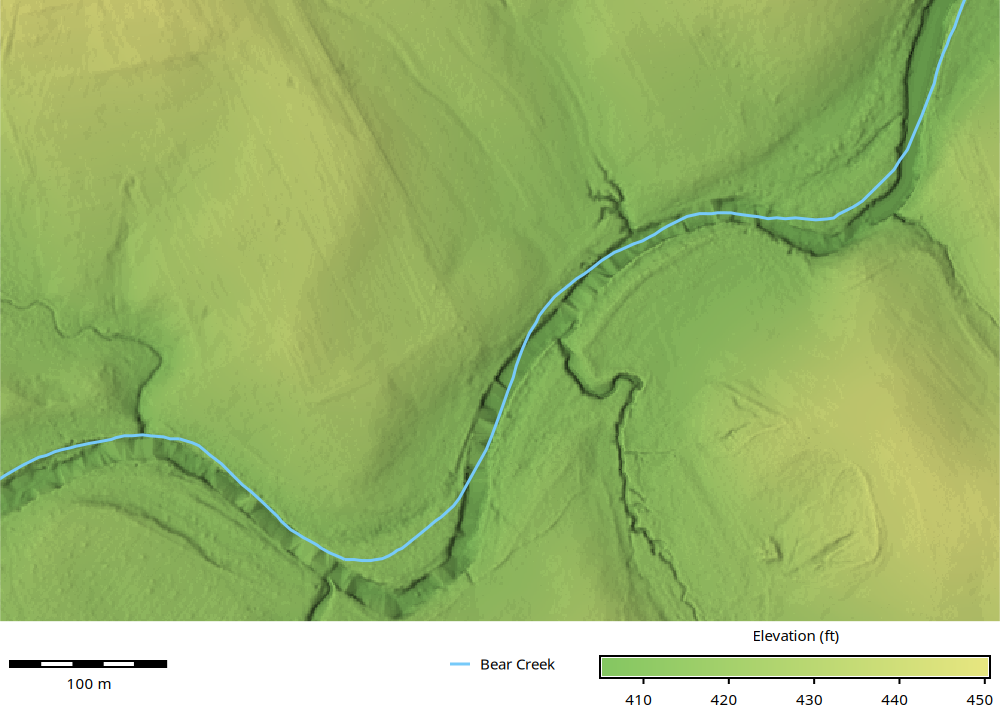

In [13]:
with gs.RegionManager(region="zoom_1", s="s-300"):
    detail_map = gj.Map(use_region=True, width=1000)
    detail_map.d_shade(color="dtm", shade="skyview_relief")
    detail_map.d_vect(map="bear_creek", width=3, color="#77caf9", legend_label="Bear Creek")
    detail_map.d_graph(color="white", stdin=io.StringIO("polygon\n0 0\n0 13\n100 13\n100 0"))
    detail_map.d_barscale(
        style="classic", at=[0, 9], text_position="under", units="meters", length=100, segment=5, fontsize=15
    )
    stats = tools.r_univar(map="dtm", format="json")
    detail_map.d_legend(
        raster="dtm",
        label_step=10,
        range=[stats["min"], stats["max"]],
        flags="t",
        fontsize=15,
        at=[5, 8, 60, 99],
        title="Elevation (ft)",
    )
    detail_map.d_legend_vect(at=[45, 9], fontsize=15)
    detail_map.show()

## 2. Stream network delineation

The bank extraction requires a stream centerline located inside the channel resolved by the lidar DTM.
The NHD flowline was compiled from older and coarser sources and deviates from the lidar channel by several meters in places,
so the stream is derived from the DTM itself.

Flow accumulation, drainage direction and the stream network are computed in a single pass with
[r.watershed](https://grass.osgeo.org/grass-stable/manuals/r.watershed.html), which implements the least-cost search algorithm
of Ehlschlaeger (1989) and therefore does not require depression filling. Streams are initiated at a flow accumulation
threshold of 50 000 cells (4.5 ha). The `b` flag post-processes flat areas so that drainage directions, and hence the stream line,
follow a more natural course through the hydro-flattened sections of the channel, such as the one in reach A, instead of running
straight across them.
The drainage direction raster is reused by the stream ordering and the HAND computation below.

In [14]:
tools.r_watershed(
    elevation="dtm",
    accumulation="accumulation",
    flags="b",
    threshold=50000,
    drainage="direction",
    stream="streams",
)

### 2.1 Main stem identification

The extracted network consists of thousands of segments. The main stem is identified with the
[r.stream.order](https://grass.osgeo.org/grass-stable/manuals/addons/r.stream.order.html) addon using Hack's ordering,
in which the main stem of each drainage network, traced from the outlet to the most distant source, receives order 1.
The ordering is run with the watershed mask active, which restricts the network to Bear Creek and its tributaries and
truncates streams at the watershed boundary. Segments of order 1 are then extracted and merged into continuous polylines with
[v.build.polylines](https://grass.osgeo.org/grass-stable/manuals/v.build.polylines.html).
The map shows the merged main stem over flow accumulation (logarithmic scale) in reach A.

In [15]:
tools.g_extension(extension="r.stream.order")
with gs.MaskManager("basin_mask"):
    tools.r_stream_order(
        stream_rast="streams",
        accumulation="accumulation",
        direction="direction",
        elevation="dtm",
        hack="stream_hack",
        stream_vect="stream_vector_hack",
    )

In [16]:
tools.v_extract(
    input="stream_vector_hack", where="hack = 1", output="hack_1", type="line"
)
tools.v_build_polylines(input="hack_1", output="connected_hack_1", cats="first")

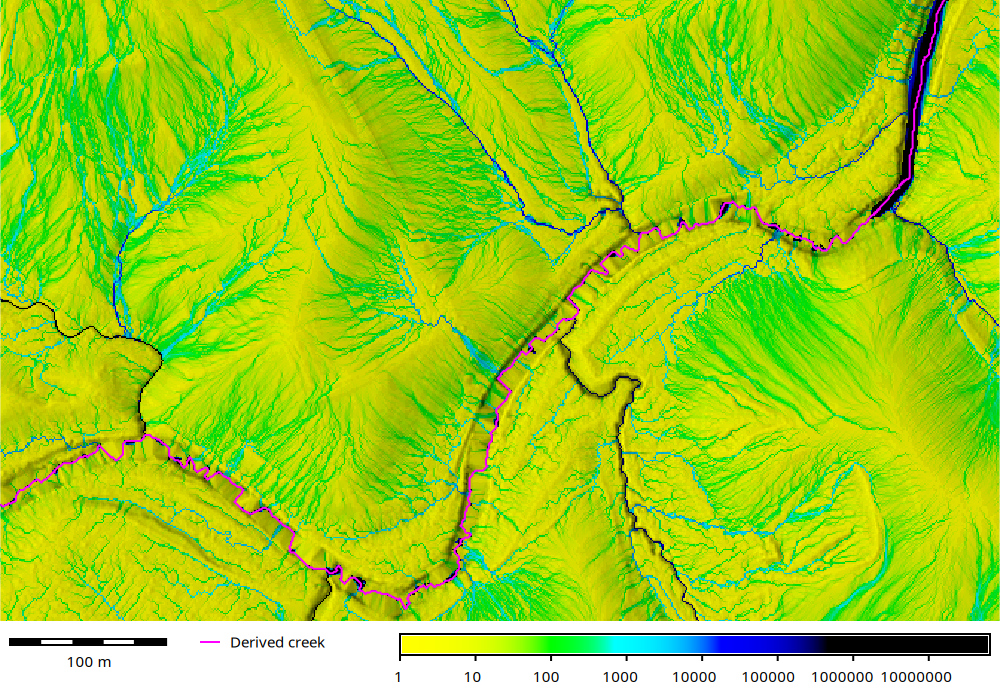

In [17]:
with gs.RegionManager(region="zoom_1", s="s-250"):
    accumulation_map = gj.Map(use_region=True, width=1000)
    accumulation_map.d_shade(color="accumulation", shade="skyview_relief")
    accumulation_map.d_vect(
        map="connected_hack_1", color="magenta", width=2, type="line", legend_label="Derived creek"
    )
    accumulation_map.d_graph(color="white", stdin=io.StringIO("polygon\n0 0\n0 10\n100 10\n100 0"))
    accumulation_map.d_barscale(
        style="classic", at=[0, 9], text_position="under", units="meters", length=100, segment=5, fontsize=15
    )
    stats = tools.r_univar(map="accumulation", format="json")
    accumulation_map.d_legend_vect(at=[20, 9], fontsize=15, columns=2)
    accumulation_map.d_legend(
        raster="accumulation",
        range=(1, stats["max"]),
        at=(5, 8, 40, 99),
        flags="tl",
        label_step=1,
        fontsize=15,
    )
    accumulation_map.show()

Apart from Bear Creek, the mask leaves a few short order 1 fragments where neighboring networks cross the watershed boundary.
Bear Creek is identified as the longest line from the lengths reported by
[v.geometry](https://grass.osgeo.org/grass-devel/manuals/v.geometry.html) as JSON and evaluated in pandas.
`v.geometry` was introduced in GRASS 8.6 as a convenience wrapper around
[v.to.db](https://grass.osgeo.org/grass-stable/manuals/v.to.db.html); use `v.to.db` in GRASS 8.5 and earlier.

In [18]:
lengths = pd.DataFrame(
    tools.v_geometry(
        map="connected_hack_1", metric="length", type="line", format="json"
    )["records"]
)
longest_cat = int(lengths.loc[lengths["length"].idxmax(), "category"])
tools.v_extract(
    input="connected_hack_1", output="longest_hack_1", type="line", cat=longest_cat
)
lengths.sort_values("length", ascending=False)

,category,length
2,2666,26219.475592
0,366,406.230036
1,1046,0.000000


A stream line traced through raster cells zigzags at the cell scale, which would bias the subsequent distance computations.
It is generalized with [v.generalize](https://grass.osgeo.org/grass-stable/manuals/v.generalize.html) in two passes:
Reumann–Witkam simplification with a 10 ft (3 m) tolerance removes the cell-scale vertices, and Chaiken's corner-cutting
algorithm smooths the remaining corners. The resulting line `stream` is the centerline used in the bank extraction;
it is compared with the NHD flowline in reach A.

In [19]:
tools.v_generalize(
    input="longest_hack_1", method="reumann", threshold=10, output="reumann"
)
tools.v_generalize(input="reumann", method="chaiken", threshold=10, output="stream")

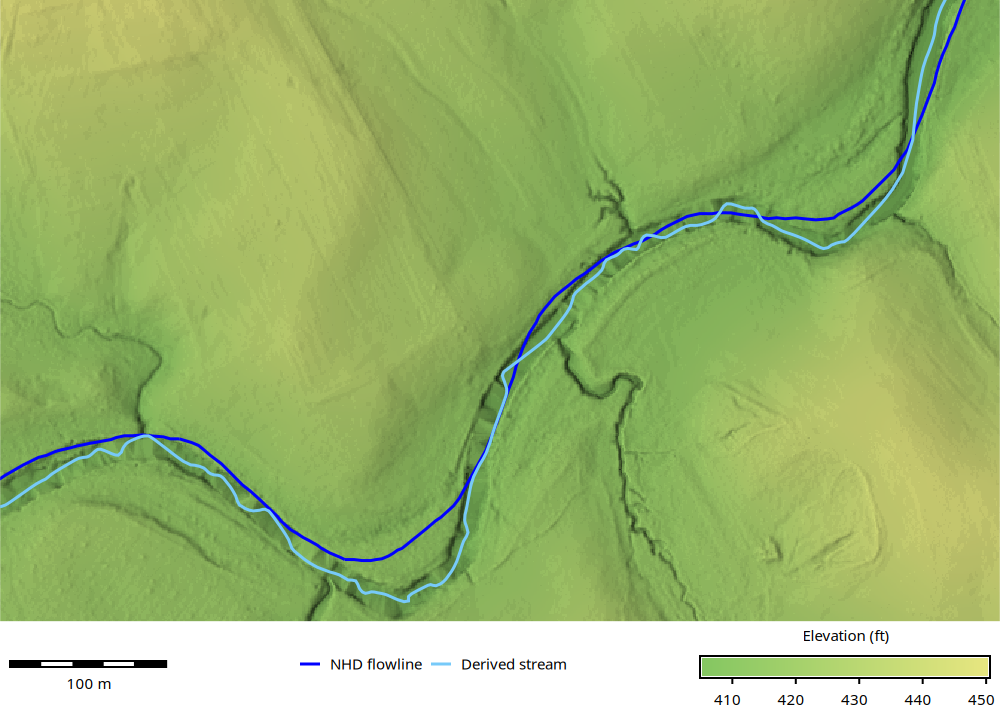

In [20]:
with gs.RegionManager(region="zoom_1", s="s-300"):
    compare_map = gj.Map(use_region=True, width=1000)
    compare_map.d_shade(color="dtm", shade="skyview_relief")
    compare_map.d_vect(map="bear_creek", color="blue", width=3, legend_label="NHD flowline")
    compare_map.d_vect(map="stream", color="#77caf9", width=3, legend_label="Derived stream")
    compare_map.d_graph(color="white", stdin=io.StringIO("polygon\n0 0\n0 13\n100 13\n100 0"))
    compare_map.d_barscale(
        style="classic", at=[0, 9], text_position="under", units="meters", length=100, segment=5, fontsize=15
    )
    compare_map.d_legend_vect(at=[30, 9], fontsize=15, columns=2)
    stats = tools.r_univar(map="dtm", format="json")
    compare_map.d_legend(
        raster="dtm",
        label_step=10,
        range=[stats["min"], stats["max"]],
        flags="t",
        fontsize=15,
        at=[5, 8, 70, 99],
        title="Elevation (ft)",
    )
    compare_map.show()

## 3. Bank extraction by least cost path analysis

The top of a stream bank is a convex break in slope. The extraction formulates bank tracing as a least cost path problem:
cells with high convex curvature are inexpensive to traverse, all other cells are expensive, and the stream centerline is
impassable. The least cost path from one end of the stream to the other on each side of the centerline then follows the bank edge.

### 3.1 Analysis corridor and terrain curvature

The analysis is confined to a corridor of 70 ft (21 m) on either side of the centerline, wide enough to contain the widest
sections of the channel, created with [v.buffer](https://grass.osgeo.org/grass-stable/manuals/v.buffer.html).
Maximum curvature is computed with [r.param.scale](https://grass.osgeo.org/grass-stable/manuals/r.param.scale.html),
which fits a bivariate quadratic surface to a moving window (here 7 × 7 cells, 22 ft or 6.7 m) following Wood (1996).
Curvature has units of inverse length and its magnitude therefore depends on the length unit of the project: computed in feet,
the values are 3.28 times smaller than in meters. The `zscale` factor of 3.28084 ft/m rescales the elevations so that the curvature
values equal those obtained in a metric CRS, which keeps the curvature threshold used below transferable to metric data.
The map shows the maximum curvature in reach A with the corridor outline: the bank edges appear as continuous
lines of high positive curvature, as do road embankments and ditches outside the corridor.

In [21]:
tools.v_buffer(input="stream", output="buffer", type="line", distance=70, flags="c")

tools.r_param_scale(
    input="dtm", output="maxcurvature", size=7, method="maxic", zscale=3.28084
)

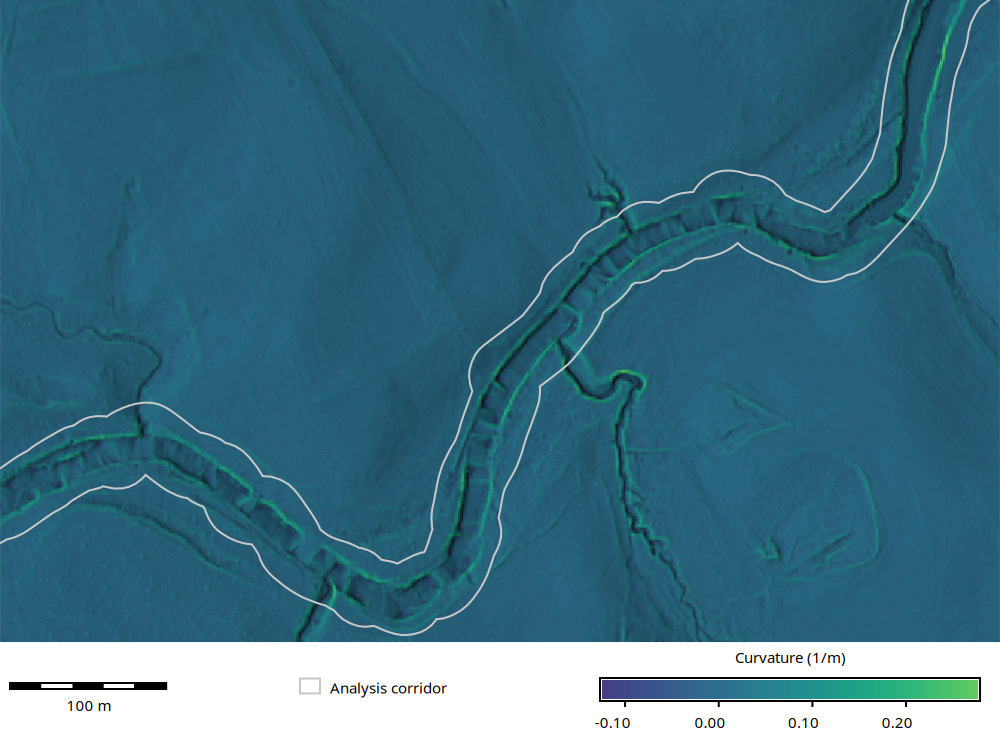

In [22]:
with gs.RegionManager(region="zoom_1", s="s-350"):
    curvature_map = gj.Map(use_region=True, width=1000)
    curvature_map.d_shade(color="maxcurvature", shade="skyview_relief")
    curvature_map.d_vect(
        map="buffer", color="200:200:200", width=2, fill_color="none", legend_label="Analysis corridor"
    )
    curvature_map.d_graph(color="white", stdin=io.StringIO("polygon\n0 0\n0 13\n100 13\n100 0"))
    curvature_map.d_barscale(
        style="classic", at=[0, 9], text_position="under", units="meters", length=100, segment=5, fontsize=15
    )
    curvature_map.d_legend_vect(at=[30, 9], fontsize=15, columns=2)
    stats = tools.r_univar(map="maxcurvature", format="json")
    curvature_map.d_legend(
        raster="maxcurvature",
        label_step=0.1,
        range=[stats["min"], stats["max"]],
        flags="t",
        fontsize=15,
        at=[5, 8, 60, 98],
        title="Curvature (1/m)",
    )
    curvature_map.show()

### 3.2 Cost surface

The cost surface is derived with map algebra ([r.mapcalc](https://grass.osgeo.org/grass-stable/manuals/r.mapcalc.html))
within a mask set to the corridor. The `MaskManager` context manager scopes the mask to the block and removes it on exit,
so that subsequent operations are unaffected. The centerline is rasterized with
[v.to.rast](https://grass.osgeo.org/grass-stable/manuals/v.to.rast.html) using densified lines (flag `d`) to ensure the
raster line has no diagonal gaps through which a path could cross.

Cell cost is assigned as follows:

| Cell | Condition | Cost |
|---|---|---|
| Stream centerline | not null in `stream` | 100 000 (impassable) |
| Bank edge | maximum curvature > 0.04 | 1 − curvature (0.56 to 0.96) |
| Other | | 100 |

The costs and the curvature threshold are empirical; only their ratios matter for the path.

In [23]:
baseline_cost = 100
stream_cost = 100000
curvature_threshold = 0.96

with gs.MaskManager():
    tools.r_mask(vector="buffer")
    tools.v_to_rast(type="line", input="stream", output="stream", use="val", flags="d")
    tools.r_mapcalc(
        expression=(
            f"cost = if(isnull(stream), "
            f"if((1 - maxcurvature) < {curvature_threshold}, 1 - maxcurvature, {baseline_cost}), "
            f"{stream_cost})"
        )
    )

### 3.3 Start and end points

Start and end points are generated with [v.segment](https://grass.osgeo.org/grass-stable/manuals/v.segment.html),
which places points at a given distance along a line and a perpendicular offset from it. The centerline is oriented
downstream, so the `start_points`, the sources of the cumulative cost computation, are placed 10 ft (3 m) from the
downstream end (negative along-line offsets are measured from the end of the line), and the `end_points` 10 ft from the
upstream end. At each end, one point is placed on either side of the centerline, 15 ft (4.6 m) from it; a positive side offset
places the point on the right side of the line, a negative one on the left. The rules are passed to the tool as an in-memory text stream.

The cost surface is shown for reach A draped over the sky-view relief within the corridor: the bank edges in yellow
(cost below 1), the baseline cost in teal and the impassable centerline in purple. The lines of low cost are interrupted
where the curvature signal of the bank is weak, so the path has to cross cells of baseline cost to connect them.
The start points lie at the outlet (reach B), outside this extent.

In [24]:
offset = 10
side_offset = 15

start_rules = (
    f"P 1 {longest_cat} -{offset} {side_offset}\n"
    f"P 2 {longest_cat} -{offset} -{side_offset}"
)
end_rules = (
    f"P 1 {longest_cat} {offset} {side_offset}\n"
    f"P 2 {longest_cat} {offset} -{side_offset}"
)
tools.v_segment(input="stream", output="start_points", rules=io.StringIO(start_rules))
tools.v_segment(input="stream", output="end_points", rules=io.StringIO(end_rules))

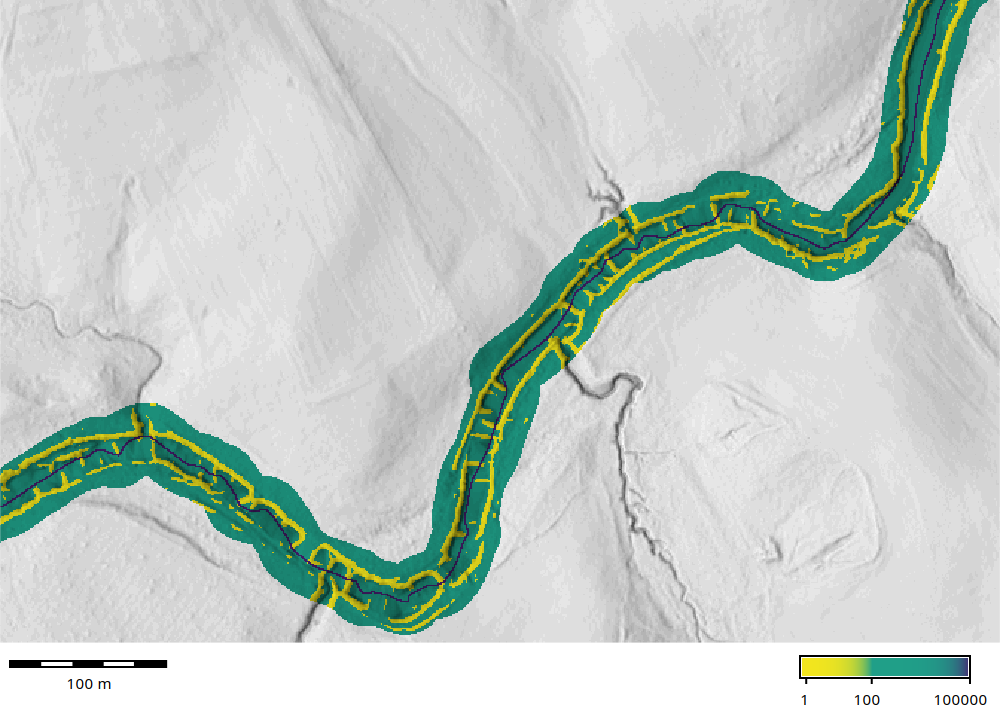

In [25]:
tools.r_colors(map="cost", rules=io.StringIO("0 #F2E51E\n1 #F2E51E\n100 #209F88\n100000 #482072"))

with gs.RegionManager(region="zoom_1", s="s-300"):
    cost_map = gj.Map(use_region=True, width=1000)
    cost_map.d_shade(color="cost", shade="skyview_relief")
    cost_map.d_vect(
        map="start_points", width=2, size=7, icon="basic/circle", color="black", fill_color="black"
    )
    cost_map.d_graph(color="white", stdin=io.StringIO("polygon\n0 0\n0 10\n100 10\n100 0"))
    cost_map.d_legend(
        raster="cost", flags="tl", label_values=[1, 100, 100000], fontsize=15, at=(5, 8, 80, 97)
    )
    cost_map.d_barscale(
        style="classic", at=[0, 9], text_position="under", units="meters", length=100, segment=5, fontsize=15
    )
    cost_map.show()

### 3.4 Least cost paths

[r.cost](https://grass.osgeo.org/grass-stable/manuals/r.cost.html) computes the cumulative cost from the start points
to every cell of the corridor (knight's move enabled for smoother paths) together with the movement direction raster.
[r.path](https://grass.osgeo.org/grass-stable/manuals/r.path.html) traces the path of least cumulative cost from each end point
back to the start points. As the centerline is impassable, each path remains on its side of the stream.
The output vector map contains two lines that inherit the categories of the end points: category 1 is the right bank and
category 2 the left bank, looking downstream.

In [26]:
tools.r_cost(
    flags="k",
    input="cost",
    output="cumulative_cost",
    outdir="costdir",
    start_points="start_points",
)
tools.r_path(input="costdir", vector_path="banks", start_points="end_points")

The extracted banks are inspected interactively against aerial imagery along the whole stream, using a
[folium](https://python-visualization.github.io/folium/) web map directly. The `grass.jupyter.Vector` class reprojects a GRASS
vector map to WGS84, converts it to GeoJSON and adds it to a folium (or ipyleaflet) map, so GRASS data can be combined with any
layer the web mapping library supports. Here two WMS layers are added: the NAIP imagery from the USGS service and the
3 ft lidar hillshade served by NC OneMap, derived from the same statewide lidar as the DTM. The imagery is drawn on top of the
hillshade; unchecking it in the layer control reveals the hillshade. As in Section 1.2, the imagery shows seams and
color differences between flight lines.
The map is fitted to the extent of the stream, obtained in geographic coordinates from `g.region`.
The imagery service renders only at larger scales, so the map must be zoomed in to a reach for the imagery to appear.

In [27]:
import folium

with gs.RegionManager(vector="stream"):
    bounds = tools.g_region(flags="b", format="json")
banks_web = folium.Map(tiles="Esri.WorldGrayCanvas", width=1000)
banks_web.fit_bounds([[bounds["ll_s"], bounds["ll_w"]], [bounds["ll_n"], bounds["ll_e"]]])
folium.WmsTileLayer(
    url="https://services.nconemap.gov/secure/services/Elevation/DEM03_hillshade/ImageServer/WMSServer",
    layers="DEM03_hillshade:hillshade",
    fmt="image/png",
    transparent=True,
    version="1.3.0",
    attr="NC OneMap, NC Emergency Management",
    name="Lidar hillshade (3 ft)",
).add_to(banks_web)
folium.WmsTileLayer(
    url="https://imagery.nationalmap.gov/arcgis/services/USGSNAIPImagery/ImageServer/WMSServer",
    layers="USGSNAIPImagery",
    fmt="image/png",
    transparent=True,
    version="1.3.0",
    attr="USGS National Agriculture Imagery Program (NAIP)",
    name="NAIP imagery",
).add_to(banks_web)
gj.Vector("stream").add_to(banks_web)
gj.Vector("banks", style_function=lambda feature: {"color": "black"}).add_to(banks_web)
folium.LayerControl().add_to(banks_web)
banks_web

The extracted banks are rendered over the sky-view relief for the two detail reaches: reach B at the outlet,
where the least cost paths start, and reach A, where both the hydro-flattened and the faceted sections
of the channel bottom lie between the banks. In both reaches the bank lines follow the break in slope at the top of the
channel on either side of the centerline.


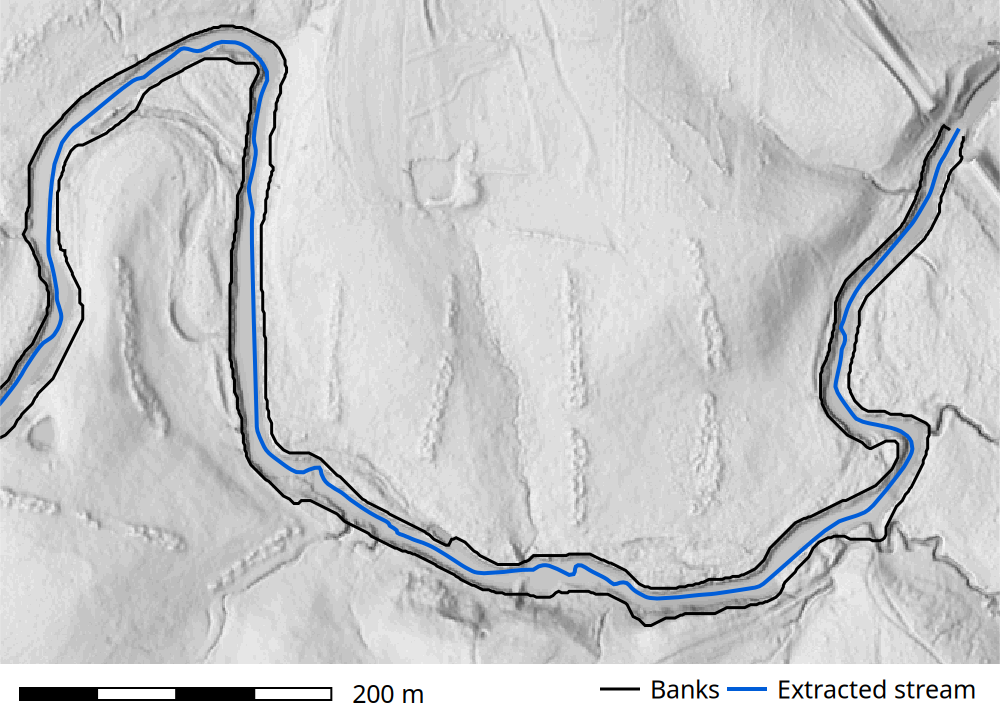

In [28]:
with gs.RegionManager(region="zoom_2", s="s-250"):
    zoomed = gj.Map(use_region=True, width=1000)
    zoomed.d_rast(map="skyview_relief")
    zoomed.d_vect(map="banks", width=3, color="black", legend_label="Banks")
    zoomed.d_vect(map="stream", width=4, color="#005dd8", legend_label="Extracted stream")
    zoomed.d_graph(color="white", stdin=io.StringIO("polygon\n0 0\n0 7\n100 7\n100 0"))
    zoomed.d_barscale(
        style="classic", at=[0, 7], units="meters", length=200, segment=4, fontsize=25, width_scale=2
    )
    zoomed.d_legend_vect(at=[60, 7], columns=2, fontsize=25, symbol_size=40)
    zoomed.show()

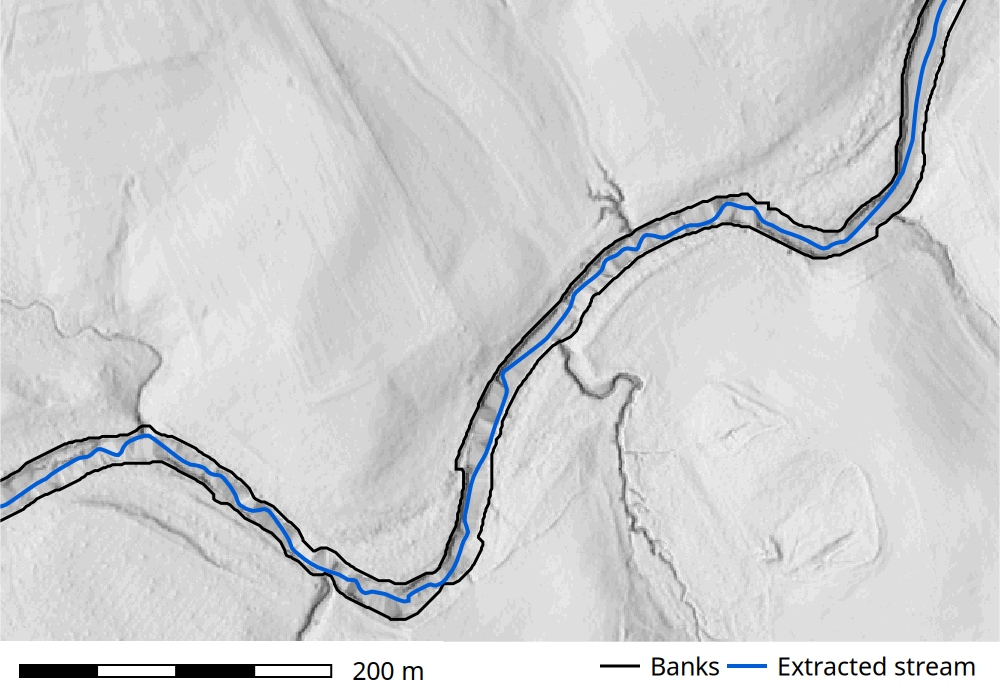

In [29]:
with gs.RegionManager(region="zoom_1", s="s-250"):
    zoomed = gj.Map(use_region=True, width=1000)
    zoomed.d_rast(map="skyview_relief")
    zoomed.d_vect(map="banks", width=3, color="black", legend_label="Banks")
    zoomed.d_vect(map="stream", width=4, color="#005dd8", legend_label="Extracted stream")
    zoomed.d_graph(color="white", stdin=io.StringIO("polygon\n0 0\n0 7\n100 7\n100 0"))
    zoomed.d_barscale(
        style="classic", at=[0, 7], units="meters", length=200, segment=4, fontsize=25, width_scale=2
    )
    zoomed.d_legend_vect(at=[60, 7], columns=2, fontsize=25, symbol_size=40)
    zoomed.show()

## 4. Channel geometry along the stream

The bank lines are converted into a longitudinal description of the channel: its width, the height of each bank above
the water surface, the difference between the two banks, and the elevation of the channel bottom.

### 4.1 Sampling points and bank height

The two banks are extracted by category into `right_bank` and `left_bank` and densified into points at 20 ft (6 m) spacing with
[v.to.points](https://grass.osgeo.org/grass-stable/manuals/v.to.points.html); the points are stored in layer 2 of the output
together with the attribute `along`, the distance from the upstream end of the line.

Bank height is expressed as Height Above Nearest Drainage (HAND), computed with the
[r.stream.distance](https://grass.osgeo.org/grass-stable/manuals/addons/r.stream.distance.html) addon from the stream raster,
the flow direction and the DTM: for every cell, the elevation difference to the stream cell reached by following the flow direction.
HAND and the DTM are sampled at the bank points with
[v.what.rast](https://grass.osgeo.org/grass-stable/manuals/v.what.rast.html) into the columns `hand_right`, `dtm_right`,
`hand_left` and `dtm_left`.
Because the DTM in the channel represents the water surface or an interpolated surface rather than the bed (Section 1),
HAND measures bank height above that surface, and the channel bottom elevation derived from it inherits the flat reaches
and triangular artifacts of the DTM.

In [30]:
spacing = 20  # ft

tools.v_extract(input="banks", cats="1", output="right_bank")
tools.v_extract(input="banks", cats="2", output="left_bank")
tools.v_to_points(input="right_bank", output="right_bank_points", dmax=spacing)
tools.v_to_points(input="left_bank", output="left_bank_points", dmax=spacing)

In [31]:
tools.g_extension(extension="r.stream.distance")
tools.r_stream_distance(
    stream_rast="streams", direction="direction", elevation="dtm", difference="hand"
)

In [32]:
tools.v_what_rast(map="right_bank_points", raster="hand", column="hand_right", layer=2)
tools.v_what_rast(map="right_bank_points", raster="dtm", column="dtm_right", layer=2)
tools.v_what_rast(map="left_bank_points", raster="hand", column="hand_left", layer=2)
tools.v_what_rast(map="left_bank_points", raster="dtm", column="dtm_left", layer=2)

### 4.2 Channel width

Channel width is obtained as the distance from each point on the right bank to the nearest point on the left bank with
[v.distance](https://grass.osgeo.org/grass-stable/manuals/v.distance.html), which also transfers the HAND and elevation
of that nearest point into the attribute table of the right bank, so that each right bank point carries the width and the
properties of both banks. The resulting attribute table, with all values in feet, is shown below.


In [33]:
tools.v_db_addcolumn(
    map="right_bank_points",
    column="width double precision,hand_left double precision,dtm_left double precision",
    layer=2,
)
tools.v_distance(
    from_="right_bank_points",
    from_layer=2,
    to="left_bank_points",
    to_layer=2,
    upload="dist,to_attr",
    to_column="hand_left",
    column="width,hand_left",
)
tools.v_distance(
    from_="right_bank_points",
    from_layer=2,
    to="left_bank_points",
    to_layer=2,
    upload="to_attr",
    to_column="dtm_left",
    column="dtm_left",
)

In [34]:
pd.DataFrame(
    tools.v_db_select(map="right_bank_points", format="json", layer=2)["records"]
)

,cat,lcat,along,hand_right,dtm_right,width,hand_left,dtm_left
0,1,1,0.000000,0.429260,563.0947,28.811076,1.288757,563.8458
1,2,1,19.996945,1.047058,563.6041,28.810916,0.932434,563.4895
2,3,1,39.993890,3.571167,563.4965,28.810756,0.107056,562.9264
3,4,1,59.990836,2.775696,562.7010,33.901012,0.000000,562.3793
4,5,1,79.987781,2.606689,562.5320,43.089424,0.317688,562.5104
...,...,...,...,...,...,...,...,...
3508,3509,1,70149.283934,7.943604,403.3836,60.286936,7.310303,402.7503
3509,3510,1,70169.280880,7.191711,402.6317,64.224284,7.693237,403.1332
3510,3511,1,70189.277825,5.626648,401.0667,55.510355,0.237213,395.6772
3511,3512,1,70209.274770,1.405273,396.8453,40.418422,0.237213,395.6772


The table is read as JSON into a pandas DataFrame, converted to meters (distance along the stream to kilometers)
and extended with the channel bottom elevation, the lower, mean and higher of the two bank heights, and their difference.

The channel bottom elevation is derived as the bank elevation minus HAND rather than by sampling the DTM along the centerline.
HAND is the elevation difference between a bank cell and the stream cell it drains to, so the difference is the elevation of a raster
stream cell, and bank top, bank height and channel bottom at each station refer to the same point and share the same distance along the bank.

In [35]:
FT_TO_M = 0.3048

df = pd.DataFrame(
    tools.v_db_select(
        map="right_bank_points",
        layer=2,
        columns="along,hand_right,dtm_right,width,hand_left,dtm_left",
        format="json",
    )["records"]
)
df = (
    df.apply(pd.to_numeric, errors="coerce").sort_values("along").reset_index(drop=True)
)
df *= FT_TO_M  # all columns to meters
df["along"] /= 1000  # distance along the stream in km

# channel bottom elevation estimated from each bank and averaged
df["bottom_right"] = df.dtm_right - df.hand_right
df["bottom_left"] = df.dtm_left - df.hand_left
df["bottom"] = (df.bottom_right + df.bottom_left) / 2

# bank height statistics across the two banks
df["hand_low"] = df[["hand_right", "hand_left"]].min(axis=1)  # controls overtopping
df["hand_mean"] = df[["hand_right", "hand_left"]].mean(axis=1)
df["hand_high"] = df[["hand_right", "hand_left"]].max(axis=1)
df["hand_diff"] = df.hand_right - df.hand_left
df.describe().round(2)

,along,hand_right,dtm_right,width,hand_left,dtm_left,bottom_right,bottom_left,bottom,hand_low,hand_mean,hand_high,hand_diff
count,3513.00,3513.00,3513.00,3513.00,3513.00,3513.00,3513.00,3513.00,3513.00,3513.00,3513.00,3513.00,3513.00
mean,10.70,1.39,140.03,15.12,1.22,139.84,138.63,138.62,138.63,1.06,1.31,1.55,0.18
std,6.18,0.82,12.18,6.02,0.58,12.29,12.66,12.67,12.66,0.55,0.61,0.78,0.73
min,0.00,-0.18,120.96,2.72,-0.12,120.60,120.53,120.53,120.53,-0.18,0.00,0.00,-3.98
25%,5.35,0.90,128.86,11.08,0.83,128.90,127.07,127.07,127.08,0.68,0.89,1.06,-0.20
50%,10.70,1.29,138.50,14.30,1.18,138.37,137.06,137.06,137.07,1.05,1.23,1.42,0.09
75%,16.05,1.76,148.87,18.02,1.58,148.73,147.58,147.79,147.68,1.43,1.67,1.94,0.43
max,21.41,5.85,171.79,46.35,3.98,171.86,171.50,171.55,171.48,2.61,3.89,5.85,4.79


### 4.3 Longitudinal profile

The profile below plots, against the distance along the stream, the channel width, the height of the lower, mean and higher bank,
the difference between the right and left bank heights, and the elevation of the channel bottom.
Values at 6 m spacing are shown in light colors and a 30-point (about 180 m) rolling mean in full color.

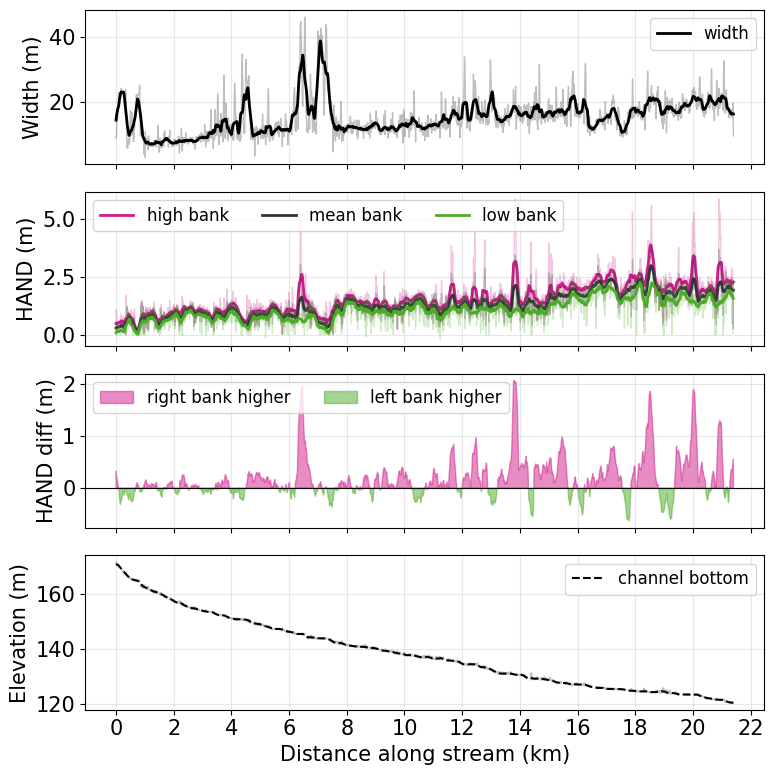

In [36]:
from matplotlib.ticker import MultipleLocator

SMOOTH = 30  # rolling window (points, about 180 m)
C_HIGH, C_MEAN, C_LOW = "#D01C8B", "#2F3538", "#4DAC26"
plt.rcParams.update({"font.size": 15})

def smooth(series):
    return series.rolling(SMOOTH, center=True, min_periods=1).mean()


def line(ax, column, color, label):
    ax.plot(df.along, df[column], color=color, alpha=0.25, lw=1)
    ax.plot(df.along, smooth(df[column]), color=color, lw=2, label=label)


fig, axes = plt.subplots(4, 1, sharex=True, figsize=(8, 8))

line(axes[0], "width", "k", "width")
axes[0].set_ylabel("Width (m)")

line(axes[1], "hand_high", C_HIGH, "high bank")
line(axes[1], "hand_mean", C_MEAN, "mean bank")
line(axes[1], "hand_low", C_LOW, "low bank")
axes[1].set_ylabel("HAND (m)")

d = smooth(df.hand_diff)
axes[2].fill_between(
    df.along, 0, d, where=d >= 0, color=C_HIGH, alpha=0.5, label="right bank higher"
)
axes[2].fill_between(
    df.along, 0, d, where=d < 0, color=C_LOW, alpha=0.5, label="left bank higher"
)
axes[2].axhline(0, color="k", lw=0.8)
axes[2].set_ylabel("HAND diff (m)")

axes[3].plot(df.along, df.bottom, "k--", lw=1.5, alpha=0.25)
axes[3].plot(df.along, smooth(df.bottom), "k--", lw=1.5, label="channel bottom")
axes[3].set_ylabel("Elevation (m)")
axes[3].set_xlabel("Distance along stream (km)")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(loc="best", fontsize=12, ncols=3)
    ax.xaxis.set_major_locator(MultipleLocator(2))
# fig.suptitle("Longitudinal bank profile of Bear Creek")
fig.tight_layout()

Along its 21 km course, Bear Creek widens from about 8 m in the headwaters to 15 to 20 m in the lower reaches,
and its banks rise from about 0.5 m to about 2 m above the water surface, while the channel bottom descends 50 m,
a mean gradient of 2.3 m/km that is steepest in the first few kilometers. The widest reach, between km 6 and 8, is examined in Section 4.4. Short spikes in width and bank height coincide
with road crossings, tributary confluences and reaches where the least cost path departs from the bank edge;
these locations can be inspected in the map and corrected by adjusting the corridor width, the curvature window or the cost thresholds.
The difference between the banks reveals the asymmetry of the channel: the right bank is higher along most of the lower two thirds
of the stream, whereas the left bank is higher in the headwaters and in a few short reaches downstream of km 17.

### 4.4 Detail of the widest reach

The width profile stands out between km 6 and 8, where the channel is up to 40 m wide. To inspect this reach, the right bank
points in that interval are selected by their `along` attribute with [v.db.select](https://grass.osgeo.org/grass-stable/manuals/v.db.select.html),
whose `r` flag returns the extent of the selected features instead of their attributes. The extent, enlarged by 100 cells, defines the
computational region for rendering the banks and the centerline over the sky-view relief.

In [37]:
range_km = (6, 8)
range_ft = [km * 1000 / FT_TO_M for km in range_km]
zoom = tools.v_db_select(
    map="right_bank_points",
    layer=2,
    flags="r",
    format="json",
    where=f"along > {range_ft[0]} and along < {range_ft[1]}",
)["extent"]

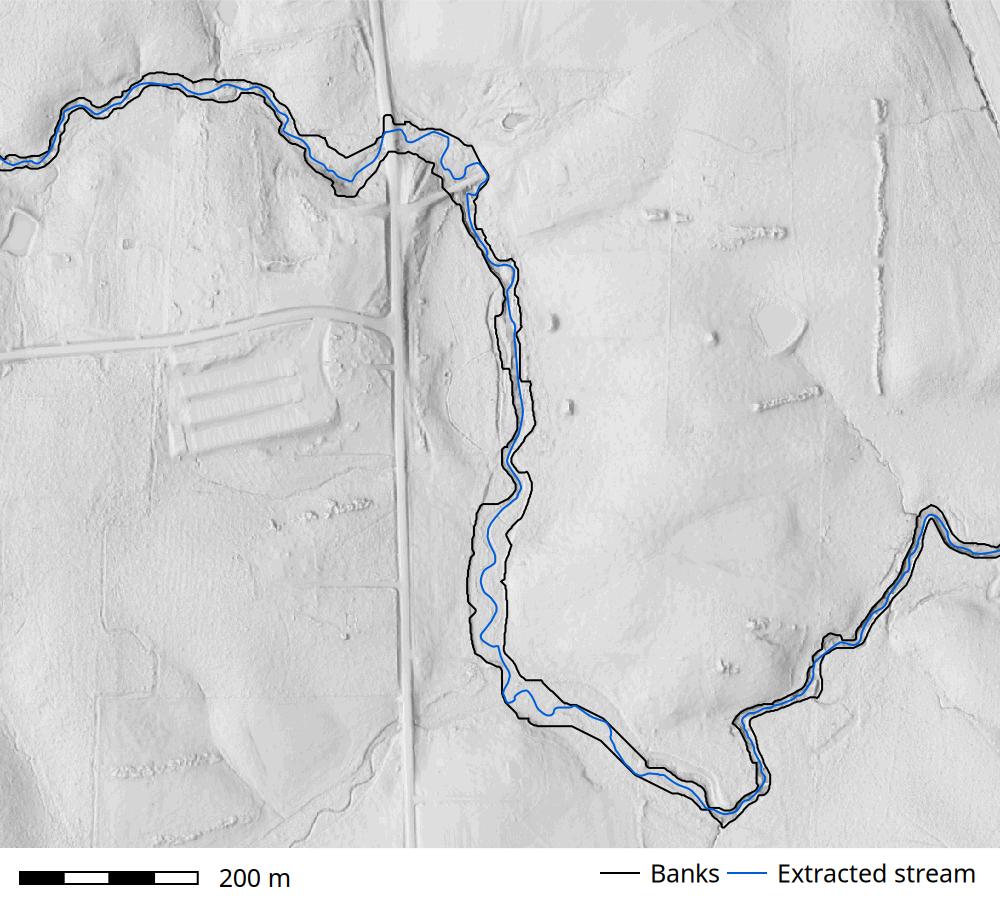

In [38]:
with gs.RegionManager(grow=100, **zoom):
    zoomed = gj.Map(use_region=True, width=1000)
    zoomed.d_rast(map="skyview_relief")
    zoomed.d_vect(map="banks", width=2, color="black", legend_label="Banks")
    zoomed.d_vect(map="stream", width=2, color="#005dd8", legend_label="Extracted stream")
    zoomed.d_graph(color="white", stdin=io.StringIO("polygon\n0 0\n0 7\n100 7\n100 0"))
    zoomed.d_barscale(
        style="classic", at=[0, 7], units="meters", length=200, segment=4, fontsize=25, width_scale=2
    )
    zoomed.d_legend_vect(at=[60, 7], columns=2, fontsize=25, symbol_size=40)
    zoomed.show()

## References

- Ehlschlaeger, C. R. (1989). Using the A<sup>T</sup> search algorithm to develop hydrologic models from digital elevation data.
  *Proceedings of the International Geographic Information System (IGIS) Symposium*, Baltimore, MD, 275–281.
- Jasiewicz, J. and Metz, M. (2011). A new GRASS GIS toolkit for Hortonian analysis of drainage networks. *Computers & Geosciences*, 37(8), 1162–1173.
- Nobre, A. D. et al. (2011). Height Above the Nearest Drainage – a hydrologically relevant new terrain model. *Journal of Hydrology*, 404(1–2), 13–29.
- Wood, J. (1996). *The geomorphological characterisation of digital elevation models*. PhD thesis, University of Leicester.
- Zakšek, K., Oštir, K. and Kokalj, Ž. (2011). Sky-view factor as a relief visualization technique. *Remote Sensing*, 3(2), 398–415.